# 02. Digital Filter Design & Frequency-Domain Analysis

This notebook explores the spectral content of raw ECG signals and examines the classical digital filters designed to isolate clinical cardiac features.

### Noise Sources in ECG:
1. **Baseline Wander** ($< 0.5$ Hz): Caused by respiration and body movement.
2. **Power-Line Interference** ($50$ Hz): Electromagnetic interference from mains electricity.
3. **High-Frequency Muscle Noise / EMG** ($> 40$ Hz): Skeletal muscle tremors and RF noise.

### Filter Pipeline:
$$\text{Raw ECG} \xrightarrow{\text{High-pass (0.5 Hz)}} \xrightarrow{\text{Notch (50 Hz)}} \xrightarrow{\text{Low-pass (40 Hz)}} \text{Clean ECG}$$
Using zero-phase bidirectional filtering (`filtfilt`) to prevent phase distortion.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data_loader import load_record
from src.frequency_analysis import compute_fft, compute_power_spectrum
from src.filters import get_highpass_response, get_notch_response, get_lowpass_response
from src.preprocessing import preprocess_ecg
from src import config

## 1. Frequency Spectrum of Raw ECG

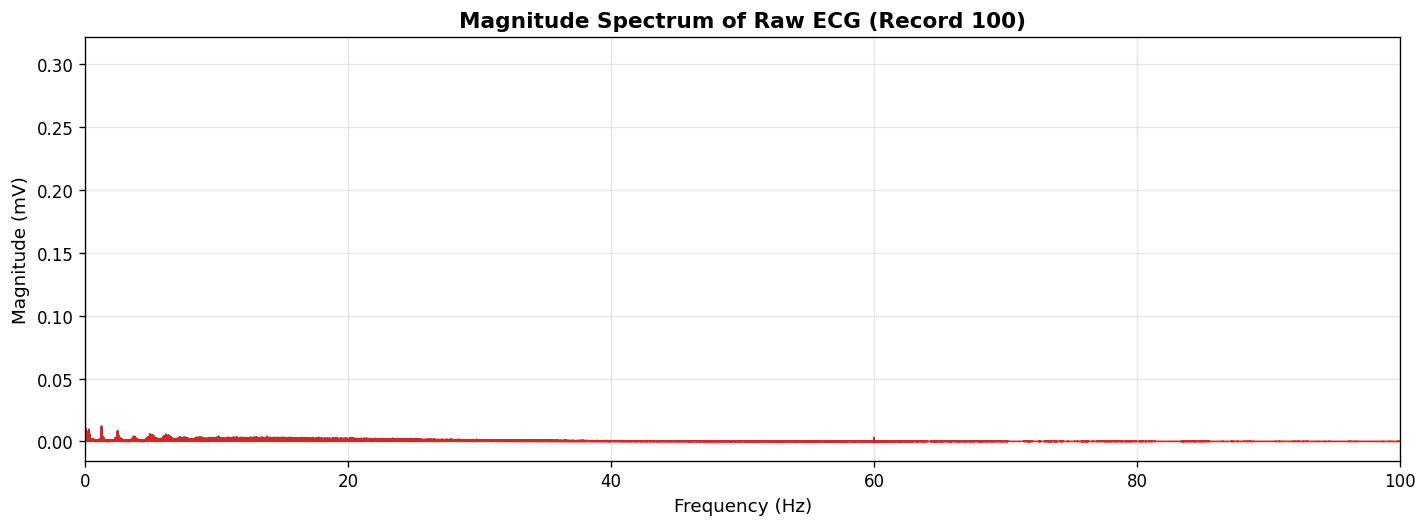

In [2]:
ecg = load_record('100')
freqs_raw, mag_raw = compute_fft(ecg.signal, ecg.sampling_frequency)

plt.figure(figsize=(12, 4.5), dpi=120)
plt.plot(freqs_raw, mag_raw, color='#d62728', lw=1.0)
plt.title('Magnitude Spectrum of Raw ECG (Record 100)', fontsize=13, fontweight='bold')
plt.xlabel('Frequency (Hz)', fontsize=11)
plt.ylabel('Magnitude (mV)', fontsize=11)
plt.xlim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Frequency Response of Digital Filters
We inspect the magnitude responses of the High-pass (0.5 Hz), Notch (50 Hz), and Low-pass (40 Hz) stages.

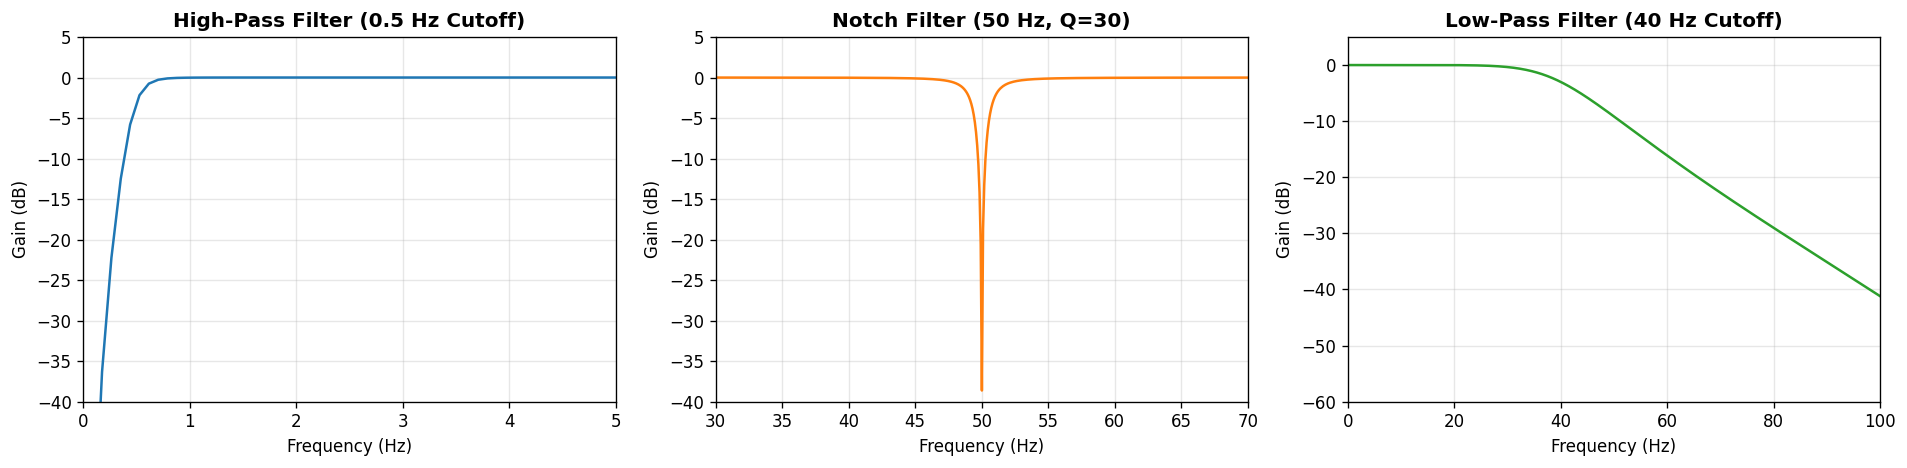

In [3]:
hp_freqs, hp_mag = get_highpass_response(ecg.sampling_frequency)
notch_freqs, notch_mag = get_notch_response(ecg.sampling_frequency)
lp_freqs, lp_mag = get_lowpass_response(ecg.sampling_frequency)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=120)

axes[0].plot(hp_freqs, hp_mag, color='#1f77b4', lw=1.5)
axes[0].set_title('High-Pass Filter (0.5 Hz Cutoff)', fontweight='bold')
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Gain (dB)')
axes[0].set_xlim(0, 5)
axes[0].set_ylim(-40, 5)
axes[0].grid(True, alpha=0.3)

axes[1].plot(notch_freqs, notch_mag, color='#ff7f0e', lw=1.5)
axes[1].set_title('Notch Filter (50 Hz, Q=30)', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Gain (dB)')
axes[1].set_xlim(30, 70)
axes[1].set_ylim(-40, 5)
axes[1].grid(True, alpha=0.3)

axes[2].plot(lp_freqs, lp_mag, color='#2ca02c', lw=1.5)
axes[2].set_title('Low-Pass Filter (40 Hz Cutoff)', fontweight='bold')
axes[2].set_xlabel('Frequency (Hz)')
axes[2].set_ylabel('Gain (dB)')
axes[2].set_xlim(0, 100)
axes[2].set_ylim(-60, 5)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Comparison Before and After Filtering
Clean the signal and compare the waveform and power spectrum.

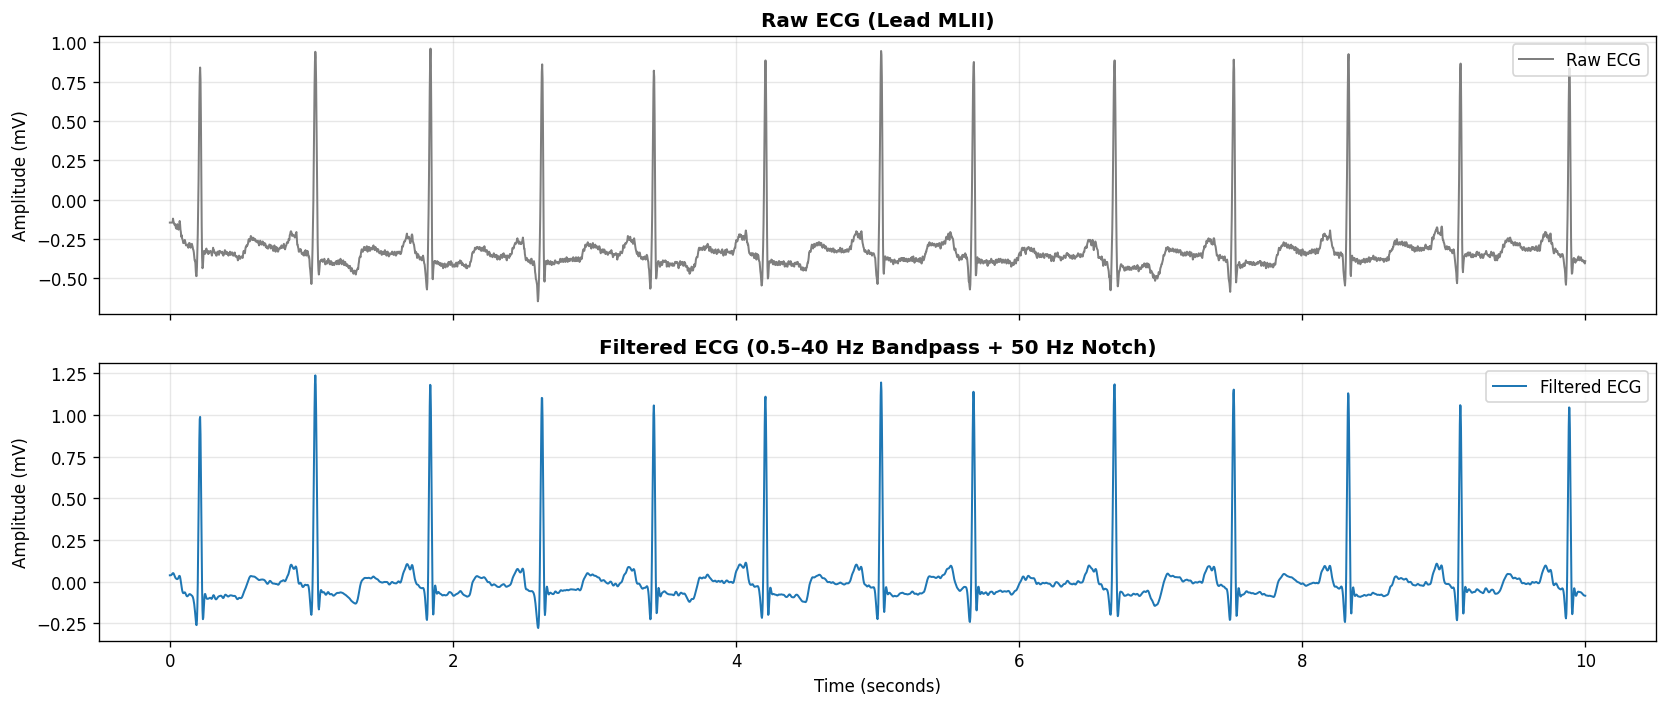

In [4]:
ecg_clean = preprocess_ecg(ecg.signal, ecg.sampling_frequency)
freqs_clean, mag_clean = compute_fft(ecg_clean, ecg.sampling_frequency)

t_mask = ecg.time <= 10.0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True, dpi=120)
ax1.plot(ecg.time[t_mask], ecg.signal[t_mask], color='#7f7f7f', lw=1.2, label='Raw ECG')
ax1.set_title('Raw ECG (Lead MLII)', fontweight='bold')
ax1.set_ylabel('Amplitude (mV)')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(ecg.time[t_mask], ecg_clean[t_mask], color='#1f77b4', lw=1.2, label='Filtered ECG')
ax2.set_title('Filtered ECG (0.5–40 Hz Bandpass + 50 Hz Notch)', fontweight='bold')
ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('Amplitude (mV)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()